In [1]:
import os
import sys

import numpy as np
from matplotlib import pyplot as plt

sys.path.append('../bin')
from utils import load_corr_list
from cov_utils import get_EZmocks_covariance

from desi_file_manager import DESIFileName
from local_file_manager import LocalFileName

# plotting
plt.style.use(os.path.join(os.path.abspath('../bin'), 'plot_style.mplstyle'))
plots_dir = '../../plots/'

### Global parameters

In [2]:
# tracer
tracer = 'ELG'
region = 'GCcomb'
zrange = (1.1, 1.6)

# mocks/version
version = 'v4_1fixran'
imocks = range(25)

# multipoles
ells = (0, 2, 4)

# cut
rpcut = 0.
thetacut = 0

fn = DESIFileName()
fn.set_default_config(version=version, ftype='allcounts', tracer=tracer, region=region, baseline=False, weighting='_default_FKP_lin', nran=10, njack=0, split=20)

## Plots

In [3]:
# for zenodo
data = {"0": dict(), "2": dict(), "4": dict()}

In [4]:
## EZmock covariance
sep, cov = get_EZmocks_covariance(stat='xi', tracer=tracer, region=region, zrange=zrange, completeness='ffa', ells=ells, thetacut=thetacut, select=(0, 200, 4), return_x=True)

In [5]:
std = np.sqrt(np.diag(np.abs(cov))).reshape((len(ells), len(cov)//len(ells)))

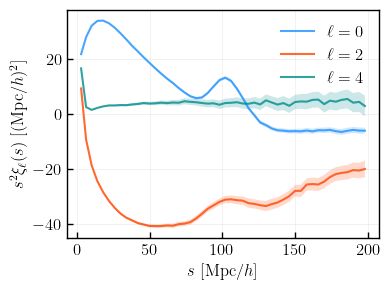

In [13]:
plt.figure(figsize = (4, 3))

fn.set_default_config(completeness=True, version=version).update(zrange=zrange)
poles = load_corr_list([fn.get_path(realization=imock, rpcut=rpcut, thetacut=thetacut) for imock in imocks], rebin=4)

for i, ell in enumerate(ells):
    plt.plot(poles['sep'][i], poles['sep'][i]**2 * poles['data'][i], color='C{}'.format(i), ls='-', alpha=0.8, label=r'$\ell = {}$'.format(ell))
    plt.fill_between(sep, sep**2 * (poles['data'][i] - std[i]/5), sep**2 * (poles['data'][i] + std[i]/5), facecolor='C{}'.format(i), alpha=0.2)
plt.ylabel(r'$s^2 \xi_\ell (s)$ [$(\mathrm{Mpc}/h)^{2}$]')
plt.xlabel('$s$ [Mpc/$h$]')  
plt.legend()
plt.savefig(os.path.join(plots_dir, version, 'corr_complete_nocut_{}_{}_z{:.1f}-{:.1f}_{}mocks.pdf'.format(tracer, region, zrange[0], zrange[1], len(imocks))), dpi=200)
plt.show()